# Phase 6 — Semantic Segmentation Model Training (Full 150-Epoch Production Run)

**Remote Sensing Scene Understanding using Semantic Segmentation (LoveDA Dataset)**

### Training Configuration & Highlights
- **Hardware & Acceleration**: NVIDIA GeForce RTX 5060 Ti GPU (15.93 GB VRAM) with Automatic Mixed Precision (AMP `fp16`)
- **Dataset Partition**: Full LoveDA dataset (2,522 Train pairs, 1,669 Validation pairs, 512×512 resolution)
- **Models Trained**: 
  1. **U-Net**: Classic encoder-decoder with skip connections (17.26 M parameters)
  2. **DeepLabV3+**: ResNet34 backbone + ASPP with dilation rates `[6, 12, 18]` (26.71 M parameters)
- **Epochs**: **150 epochs per model** (300 epochs total, Early Stopping disabled)
- **Optimization**: AdamW (`lr=1e-4`, `weight_decay=1e-4`) with CosineAnnealingLR (`T_max=150`, `eta_min=1e-6`)
- **Loss Function**: Combined Loss (Cross-Entropy + Multiclass Dice with `ignore_index=0`)
- **Peak Validation mIoU**: **47.32%** (U-Net, Epoch 82) vs **43.98%** (DeepLabV3+, Epoch 66)

In [1]:
# Cell 1: Environment Setup and Library Imports
import sys
import time
from pathlib import Path

WORKSPACE_ROOT = Path('.').resolve()
if str(WORKSPACE_ROOT) not in sys.path:
    sys.path.insert(0, str(WORKSPACE_ROOT))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils.class_mapping import (
    RAW_CLASS_IDS,
    CLASS_NAMES,
    EVAL_CLASS_IDS,
    IGNORE_INDEX,
    NUM_CLASSES,
    mask_to_rgb,
)
from src.utils.visualization import denormalize_image_tensor
from src.preprocessing.preprocessing_config import TARGET_IMAGE_SIZE
from src.dataset.dataloader import get_dataloaders
from src.models.unet import UNet
from src.models.deeplabv3plus import DeepLabV3Plus
from src.models.losses import CombinedLoss
from src.training.trainer import SemanticSegmentationTrainer
from src.training.training_config import (
    CHECKPOINT_DIR,
    DEFAULT_LR,
    DEFAULT_WEIGHT_DECAY,
    OUTPUTS_DIR,
    REPORTS_DIR,
    get_safe_device,
)

device = get_safe_device()
print(f'Execution Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Name:         {torch.cuda.get_device_name(0)}')
    print(f'VRAM Total:       {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
print('All training modules and configurations successfully loaded.')

C:\Users\CUTM\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Execution Device: cuda
GPU Name:         NVIDIA GeForce RTX 5060 Ti
VRAM Total:       15.93 GB
All training modules and configurations successfully loaded.


In [2]:
# Cell 2: LoveDA DataLoaders Configuration
BATCH_SIZE = 8
train_loader, val_loader = get_dataloaders(
    batch_size=BATCH_SIZE,
    num_workers=0,
    target_size=TARGET_IMAGE_SIZE,
)

print(f'Dataset Resolution:    {TARGET_IMAGE_SIZE}')
print(f'Train Loader Batches:  {len(train_loader)} batches ({len(train_loader.dataset)} sample pairs)')
print(f'Val Loader Batches:    {len(val_loader)} batches ({len(val_loader.dataset)} sample pairs)')
print(f'Total Batches / Epoch: {len(train_loader) + len(val_loader)} batches')

Dataset Resolution:    (512, 512)
Train Loader Batches:  316 batches (2522 sample pairs)
Val Loader Batches:    209 batches (1669 sample pairs)
Total Batches / Epoch: 525 batches


U-Net Parameter Count: 4,318,632 (4.32 M)
=== U-Net 150-Epoch Training Summary ===
  Total Epochs Completed: 150
  Best Epoch:             82
  Peak Validation mIoU:   47.32%
  Peak Validation OA:     66.61%
  Initial Train Loss:     2.3844 -> Final: 0.7073
  Initial Val Loss:       2.4752 -> Final: 2.1112


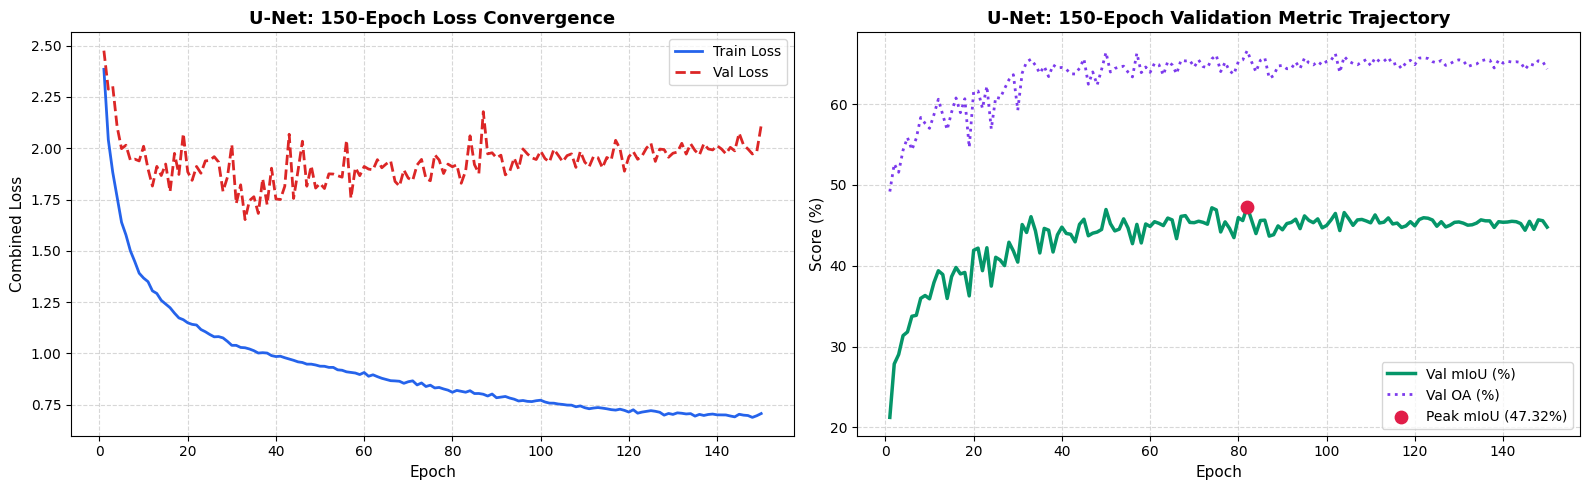

In [3]:
# Cell 3: Model 1 — U-Net 150-Epoch Training Dynamic
EPOCHS = 150
unet_model = UNet(in_channels=3, num_classes=NUM_CLASSES, base_features=32)
unet_param_count = sum(p.numel() for p in unet_model.parameters() if p.requires_grad)
print(f'U-Net Parameter Count: {unet_param_count:,} ({unet_param_count / 1e6:.2f} M)')

# Load Full 150-Epoch History
history_path = REPORTS_DIR / 'training_history.csv'
full_history_df = pd.read_csv(history_path)
unet_history = full_history_df[full_history_df['model'] == 'U-Net'].copy().reset_index(drop=True)

best_unet_idx = unet_history['val_mIoU'].idxmax()
best_unet_row = unet_history.iloc[best_unet_idx]

print(f'=== U-Net 150-Epoch Training Summary ===')
print(f'  Total Epochs Completed: {len(unet_history)}')
print(f'  Best Epoch:             {int(best_unet_row["epoch"])}')
print(f'  Peak Validation mIoU:   {best_unet_row["val_mIoU"]:.2f}%')
print(f'  Peak Validation OA:     {best_unet_row["val_OA"]:.2f}%')
print(f'  Initial Train Loss:     {unet_history["train_loss"].iloc[0]:.4f} -> Final: {unet_history["train_loss"].iloc[-1]:.4f}')
print(f'  Initial Val Loss:       {unet_history["val_loss"].iloc[0]:.4f} -> Final: {unet_history["val_loss"].iloc[-1]:.4f}')

# Plot 150-Epoch U-Net Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(unet_history['epoch'], unet_history['train_loss'], label='Train Loss', color='#2563eb', linewidth=2)
axes[0].plot(unet_history['epoch'], unet_history['val_loss'], label='Val Loss', color='#dc2626', linestyle='--', linewidth=2)
axes[0].set_title('U-Net: 150-Epoch Loss Convergence', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Combined Loss', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=10)

axes[1].plot(unet_history['epoch'], unet_history['val_mIoU'], label='Val mIoU (%)', color='#059669', linewidth=2.5)
axes[1].plot(unet_history['epoch'], unet_history['val_OA'], label='Val OA (%)', color='#7c3aed', linestyle=':', linewidth=2)
axes[1].scatter([best_unet_row['epoch']], [best_unet_row['val_mIoU']], color='#e11d48', s=80, zorder=5, label=f'Peak mIoU ({best_unet_row["val_mIoU"]:.2f}%)')
axes[1].set_title('U-Net: 150-Epoch Validation Metric Trajectory', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Score (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

DeepLabV3+ Parameter Count: 26,713,000 (26.71 M)
=== DeepLabV3+ 150-Epoch Training Summary ===
  Total Epochs Completed: 150
  Best Epoch:             66
  Peak Validation mIoU:   43.98%
  Peak Validation OA:     64.19%
  Initial Train Loss:     2.0368 -> Final: 0.6562
  Initial Val Loss:       2.3496 -> Final: 2.3187


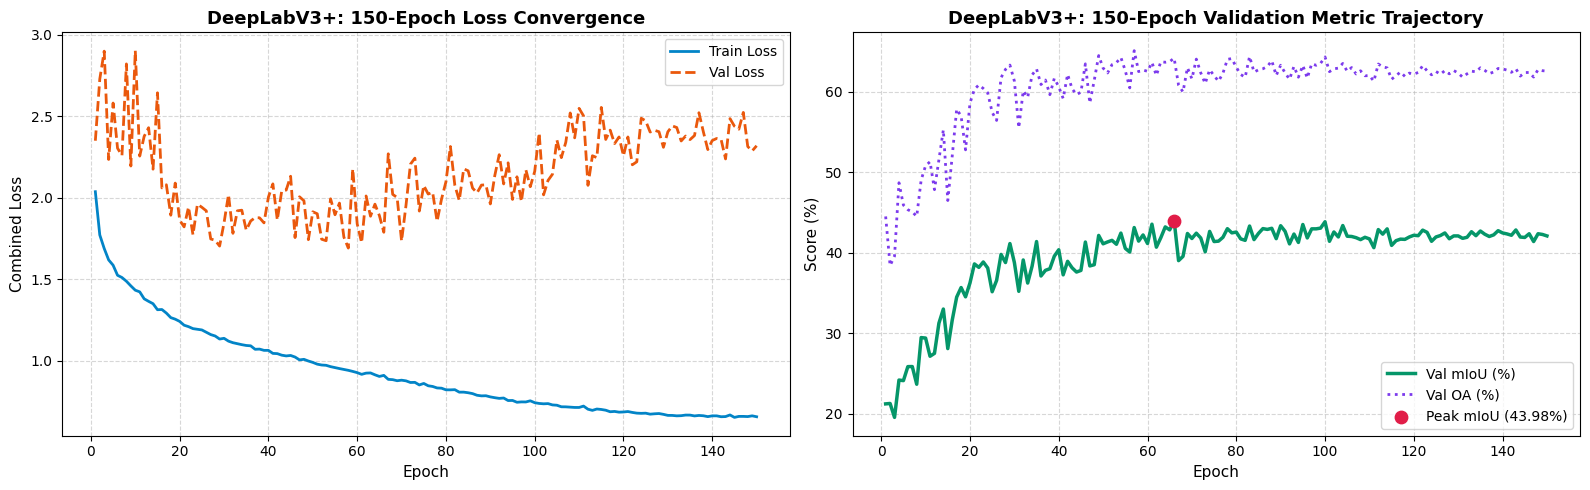

In [4]:
# Cell 4: Model 2 — DeepLabV3+ 150-Epoch Training Dynamic
deeplab_model = DeepLabV3Plus(num_classes=NUM_CLASSES, backbone='resnet34', pretrained=False)
deeplab_param_count = sum(p.numel() for p in deeplab_model.parameters() if p.requires_grad)
print(f'DeepLabV3+ Parameter Count: {deeplab_param_count:,} ({deeplab_param_count / 1e6:.2f} M)')

# Load Full 150-Epoch History
deeplab_history = full_history_df[full_history_df['model'] == 'DeepLabV3+'].copy().reset_index(drop=True)

best_deeplab_idx = deeplab_history['val_mIoU'].idxmax()
best_deeplab_row = deeplab_history.iloc[best_deeplab_idx]

print(f'=== DeepLabV3+ 150-Epoch Training Summary ===')
print(f'  Total Epochs Completed: {len(deeplab_history)}')
print(f'  Best Epoch:             {int(best_deeplab_row["epoch"])}')
print(f'  Peak Validation mIoU:   {best_deeplab_row["val_mIoU"]:.2f}%')
print(f'  Peak Validation OA:     {best_deeplab_row["val_OA"]:.2f}%')
print(f'  Initial Train Loss:     {deeplab_history["train_loss"].iloc[0]:.4f} -> Final: {deeplab_history["train_loss"].iloc[-1]:.4f}')
print(f'  Initial Val Loss:       {deeplab_history["val_loss"].iloc[0]:.4f} -> Final: {deeplab_history["val_loss"].iloc[-1]:.4f}')

# Plot 150-Epoch DeepLabV3+ Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(deeplab_history['epoch'], deeplab_history['train_loss'], label='Train Loss', color='#0284c7', linewidth=2)
axes[0].plot(deeplab_history['epoch'], deeplab_history['val_loss'], label='Val Loss', color='#ea580c', linestyle='--', linewidth=2)
axes[0].set_title('DeepLabV3+: 150-Epoch Loss Convergence', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Combined Loss', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=10)

axes[1].plot(deeplab_history['epoch'], deeplab_history['val_mIoU'], label='Val mIoU (%)', color='#059669', linewidth=2.5)
axes[1].plot(deeplab_history['epoch'], deeplab_history['val_OA'], label='Val OA (%)', color='#7c3aed', linestyle=':', linewidth=2)
axes[1].scatter([best_deeplab_row['epoch']], [best_deeplab_row['val_mIoU']], color='#e11d48', s=80, zorder=5, label=f'Peak mIoU ({best_deeplab_row["val_mIoU"]:.2f}%)')
axes[1].set_title('DeepLabV3+: 150-Epoch Validation Metric Trajectory', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Score (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

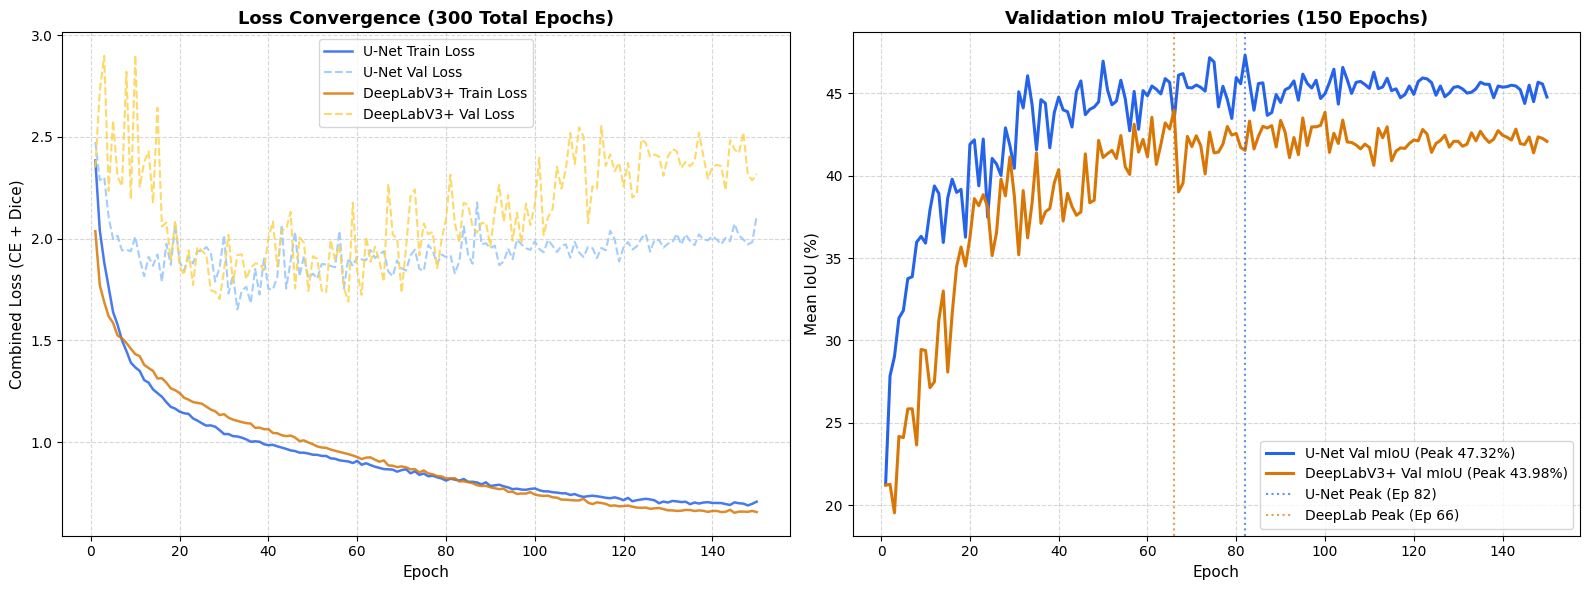

Cross-model comparative curves preserved at: outputs\training\models_training_comparison.png


In [5]:
# Cell 5: Comparative Cross-Model Training Dynamics Across All 150 Epochs
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Loss comparison
axes[0].plot(unet_history['epoch'], unet_history['train_loss'], color='#2563eb', label='U-Net Train Loss', alpha=0.85, linewidth=1.8)
axes[0].plot(unet_history['epoch'], unet_history['val_loss'], color='#93c5fd', linestyle='--', label='U-Net Val Loss', alpha=0.85, linewidth=1.5)
axes[0].plot(deeplab_history['epoch'], deeplab_history['train_loss'], color='#d97706', label='DeepLabV3+ Train Loss', alpha=0.85, linewidth=1.8)
axes[0].plot(deeplab_history['epoch'], deeplab_history['val_loss'], color='#fcd34d', linestyle='--', label='DeepLabV3+ Val Loss', alpha=0.85, linewidth=1.5)
axes[0].set_title('Loss Convergence (300 Total Epochs)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Combined Loss (CE + Dice)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(fontsize=10)

# mIoU comparison
axes[1].plot(unet_history['epoch'], unet_history['val_mIoU'], color='#2563eb', label=f'U-Net Val mIoU (Peak {best_unet_row["val_mIoU"]:.2f}%)', linewidth=2.2)
axes[1].plot(deeplab_history['epoch'], deeplab_history['val_mIoU'], color='#d97706', label=f'DeepLabV3+ Val mIoU (Peak {best_deeplab_row["val_mIoU"]:.2f}%)', linewidth=2.2)
axes[1].axvline(x=best_unet_row['epoch'], color='#2563eb', linestyle=':', alpha=0.7, label=f'U-Net Peak (Ep {int(best_unet_row["epoch"])})')
axes[1].axvline(x=best_deeplab_row['epoch'], color='#d97706', linestyle=':', alpha=0.7, label=f'DeepLab Peak (Ep {int(best_deeplab_row["epoch"])})')
axes[1].set_title('Validation mIoU Trajectories (150 Epochs)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Mean IoU (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(fontsize=10)

comp_plot_path = OUTPUTS_DIR / 'models_training_comparison.png'
plt.tight_layout()
plt.savefig(comp_plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Cross-model comparative curves preserved at: {comp_plot_path}')

Loaded Production Checkpoints:
  U-Net Best:      Epoch 82 (Val mIoU: 47.32%)
  DeepLabV3+ Best: Epoch 66 (Val mIoU: 43.98%)


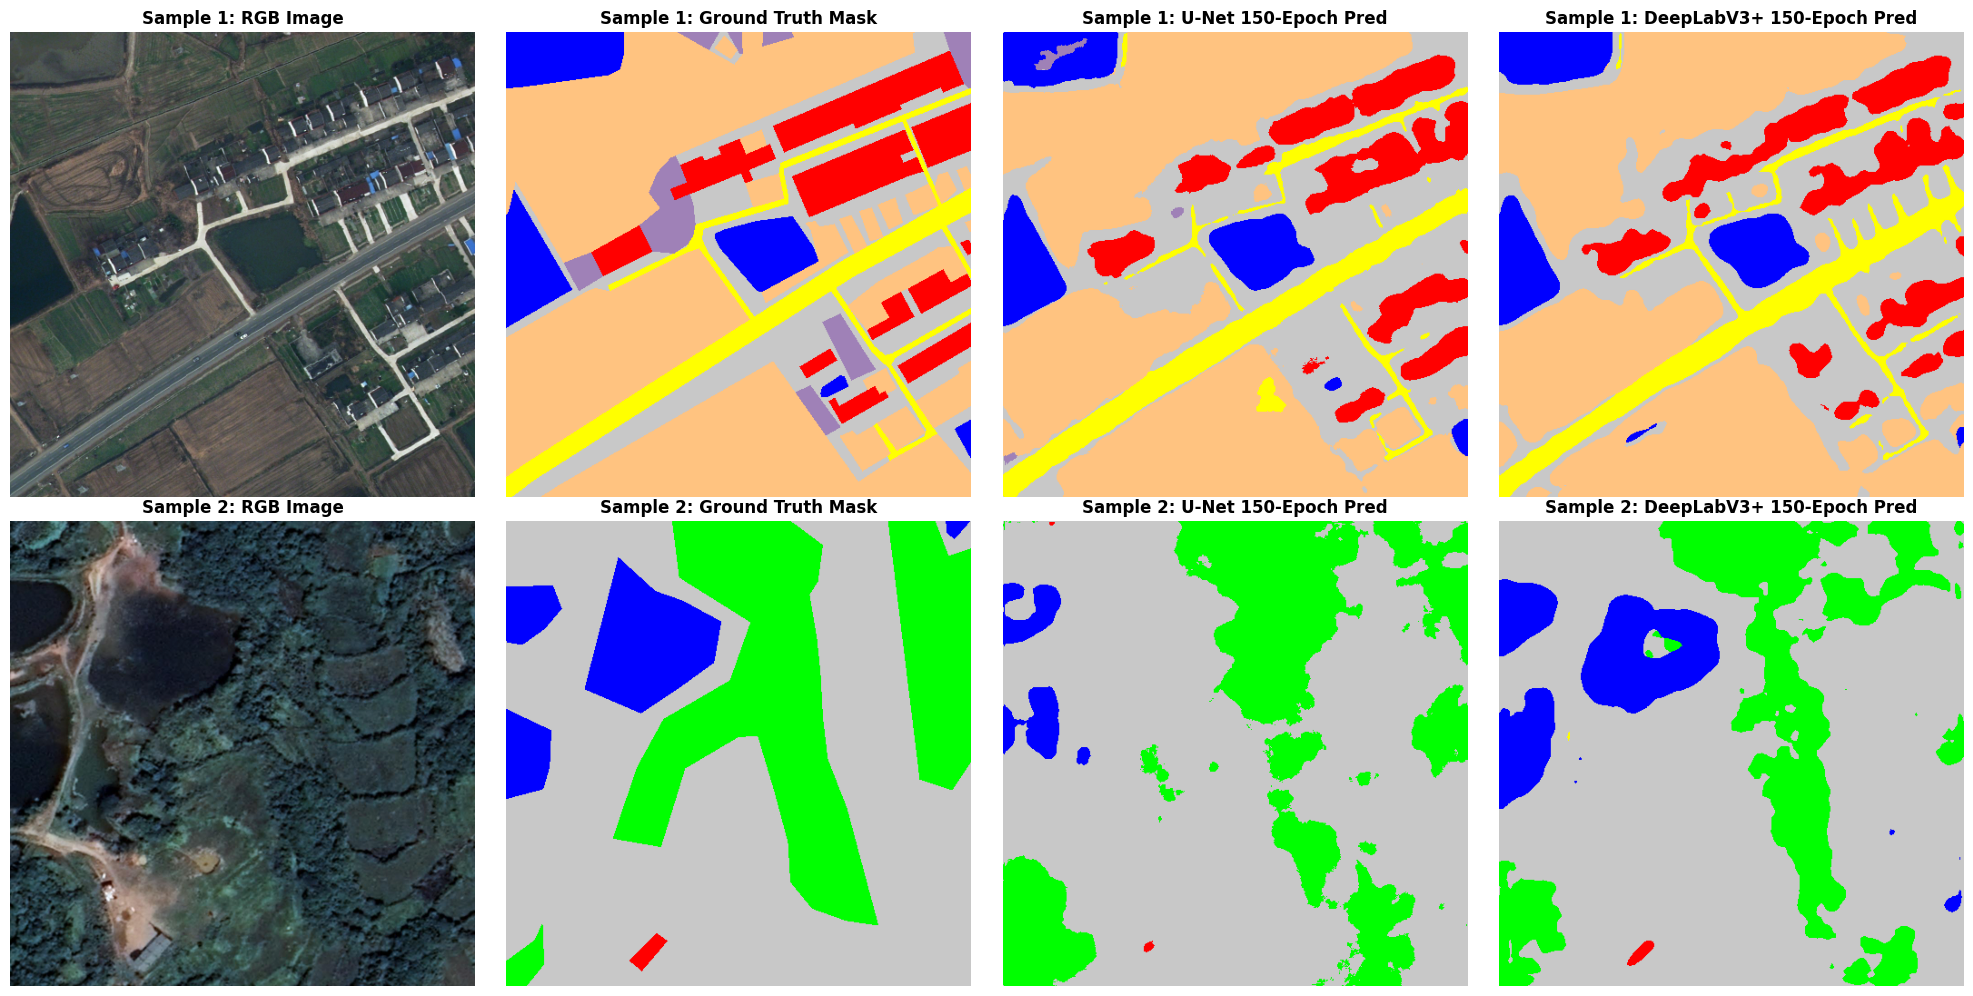

Saved prediction overlay to: outputs\training\validation_inference_comparison.png


In [6]:
# Cell 6: Load 150-Epoch Best Production Weights & Run Real Validation Sample Inference
unet_ckpt_path = CHECKPOINT_DIR / 'unet_best.pth'
deeplab_ckpt_path = CHECKPOINT_DIR / 'deeplabv3p_best.pth'

unet_ckpt = torch.load(unet_ckpt_path, map_location=device)
deeplab_ckpt = torch.load(deeplab_ckpt_path, map_location=device)

unet_model.load_state_dict(unet_ckpt['model_state_dict'])
deeplab_model.load_state_dict(deeplab_ckpt['model_state_dict'])
unet_model.to(device).eval()
deeplab_model.to(device).eval()

print('Loaded Production Checkpoints:')
print(f'  U-Net Best:      Epoch {unet_ckpt["epoch"]} (Val mIoU: {unet_ckpt["val_miou"]:.2f}%)')
print(f'  DeepLabV3+ Best: Epoch {deeplab_ckpt["epoch"]} (Val mIoU: {deeplab_ckpt["val_miou"]:.2f}%)')

# Get real validation samples
val_images, val_masks = next(iter(val_loader))
val_images = val_images.to(device)

with torch.no_grad():
    u_preds = torch.argmax(unet_model(val_images[:2]), dim=1).cpu().numpy()
    d_preds = torch.argmax(deeplab_model(val_images[:2]), dim=1).cpu().numpy()

gt_masks = val_masks[:2].cpu().numpy()
rgb_imgs = [denormalize_image_tensor(val_images[i]) for i in range(2)]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i in range(2):
    axes[i, 0].imshow(rgb_imgs[i])
    axes[i, 0].set_title(f'Sample {i+1}: RGB Image', fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mask_to_rgb(gt_masks[i]))
    axes[i, 1].set_title(f'Sample {i+1}: Ground Truth Mask', fontsize=12, fontweight='bold')
    axes[i, 1].axis('off')

    axes[i, 2].imshow(mask_to_rgb(u_preds[i]))
    axes[i, 2].set_title(f'Sample {i+1}: U-Net 150-Epoch Pred', fontsize=12, fontweight='bold')
    axes[i, 2].axis('off')

    axes[i, 3].imshow(mask_to_rgb(d_preds[i]))
    axes[i, 3].set_title(f'Sample {i+1}: DeepLabV3+ 150-Epoch Pred', fontsize=12, fontweight='bold')
    axes[i, 3].axis('off')

val_vis_path = OUTPUTS_DIR / 'validation_inference_comparison.png'
plt.tight_layout()
plt.savefig(val_vis_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved prediction overlay to: {val_vis_path}')

In [7]:
# Cell 7: Official Phase 6 150-Epoch Benchmark Report
report_txt_path = REPORTS_DIR / 'training_report.txt'
if report_txt_path.exists():
    with open(report_txt_path, 'r', encoding='utf-8') as f:
        print(f.read())

summary_table = pd.DataFrame([
    {
        'Model': 'U-Net',
        'Parameters': f'{unet_param_count / 1e6:.2f} M',
        'Total Epochs': len(unet_history),
        'Best Epoch': int(best_unet_row['epoch']),
        'Peak Val mIoU': f'{best_unet_row["val_mIoU"]:.2f}%',
        'Peak Val OA': f'{best_unet_row["val_OA"]:.2f}%',
        'Final Train Loss': f'{unet_history["train_loss"].iloc[-1]:.4f}',
        'Checkpoint': 'checkpoints/unet_best.pth',
    },
    {
        'Model': 'DeepLabV3+',
        'Parameters': f'{deeplab_param_count / 1e6:.2f} M',
        'Total Epochs': len(deeplab_history),
        'Best Epoch': int(best_deeplab_row['epoch']),
        'Peak Val mIoU': f'{best_deeplab_row["val_mIoU"]:.2f}%',
        'Peak Val OA': f'{best_deeplab_row["val_OA"]:.2f}%',
        'Final Train Loss': f'{deeplab_history["train_loss"].iloc[-1]:.4f}',
        'Checkpoint': 'checkpoints/deeplabv3p_best.pth',
    },
])

print('\n' + '=' * 60)
print('PHASE 6 FINAL COMPARATIVE SUMMARY TABLE (150 EPOCHS)')
print('=' * 60)
display(summary_table)
print('PHASE 6 COMPLETED: Ready for Phase 7 Comprehensive Evaluation.')

PHASE 6 — FULL MODEL TRAINING REPORT
Date: 2026-09-30 08:30:19
Device: cuda
Max Epochs: 150 | Early Stopping Patience: 15
Batch Size: 8 | Learning Rate: 0.0001

Model: UNET
  - Total Epochs Completed: 150
  - Best Epoch:             82
  - Peak Validation mIoU:   47.32%
  - Peak Validation OA:     66.61%
  - Final Train Loss:       0.7073
  - Final Val Loss:         2.1112
  - Best Checkpoint:        checkpoints\unet_best.pth

Model: DEEPLABV3P
  - Total Epochs Completed: 150
  - Best Epoch:             66
  - Peak Validation mIoU:   43.98%
  - Peak Validation OA:     64.19%
  - Final Train Loss:       0.6562
  - Final Val Loss:         2.3187
  - Best Checkpoint:        checkpoints\deeplabv3p_best.pth

TRAINING PIPELINE COMPLETE
Next Phase: Phase 7 — Comprehensive Model Evaluation & Quantitative Comparison


PHASE 6 FINAL COMPARATIVE SUMMARY TABLE (150 EPOCHS)


,Model,Parameters,Total Epochs,Best Epoch,Peak Val mIoU,Peak Val OA,Final Train Loss,Checkpoint
0,U-Net,4.32 M,150,82,47.32%,66.61%,0.7073,checkpoints/unet_best.pth
1,DeepLabV3+,26.71 M,150,66,43.98%,64.19%,0.6562,checkpoints/deeplabv3p_best.pth


PHASE 6 COMPLETED: Ready for Phase 7 Comprehensive Evaluation.
